# Practical 1 — Industry Classification from Business-Description Embeddings

**Goal:** given a numeric "fingerprint" (an *embedding*) of a company's business description, predict which of 25 industries the company belongs to.

**How this notebook is organised.** Every section starts with the **questions we should ask ourselves** before touching the code, then the code, then **what we learned**. Where a method is used (PCA, logistic regression, k-NN, F1, McNemar's test) there is a short box with the maths behind it.

| Section | Skeleton task |
|---|---|
| 1. First look at the data | (understanding the data) |
| 2. Train / validation split | Loading Data |
| 3. Label encoding | Transforming Data |
| 4. Class distribution | Visualize the data — over/under-represented classes |
| 5. PCA | Visualize the data — is there signal? |
| 6–8. Two classifiers, metrics, confusion matrices, error overlap | Fitting and comparing classifier models |
| 9. Preview of the bonus metric | Optional part (teaser) |
| 10. Summary | |

In [1]:
import time, json, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             precision_recall_fscore_support)

RANDOM_STATE = 42

# Plot style: two model colours (blue = logistic regression, orange = k-NN),
# a third accent colour, grey for "everything else", and quiet axes.
C_LR, C_KNN, C_ACCENT, C_GREY = "#2a78d6", "#eb6834", "#1baf7a", "#b8b7b2"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10,
})
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 60)

def short(name, width=26):
    """Wrap long industry names so they fit in plot titles/ticks."""
    return "\n".join(textwrap.wrap(name, width))

## 1. First look at the data

### Questions to ask ourselves
1. **What is one row?** One company? One description? Can the same company appear twice?
2. **What columns do we have and what are their types?** Which one is the target (what we predict) and which are features (what we predict from)?
3. **Is anything missing?**
4. **What does the embedding actually look like?** Is it already a vector of numbers or text that needs parsing? How many dimensions? What scale are the values on?
5. **How many classes are there?**

***Step 1: Import the libraries and load the data***

In [2]:
import numpy as np
import pandas as pd

df = pd.read_pickle("data/df_train.pkl")

print(df.shape)
df.head()

(31706, 3)


,id,industry,business_description_embedding
38532,42576,Banks,"[0.03411475,-0.03753958,0.023233214,-0.0017205259,-0.004..."
19838,21752,Materials,"[-0.025557408,0.0636078,-0.01350581,-0.018022388,0.02506..."
904,804,Commercial & Professional Services,"[0.033574868,-0.020379327,-0.03221274,-0.01133823,0.0214..."
28806,31603,Insurance,"[0.020648101,0.017270269,-0.032921147,-0.014111616,-0.00..."
10472,11333,Capital Goods,"[-0.0006651232,0.011097765,-0.01976973,0.022994662,-0.02..."


***Step 2:Checking data types and missing values***

In [3]:
print(df.dtypes)
print()
print(df.isna().sum())
print()
print("Number of industries:", df["industry"].nunique())
print()
first = df["business_description_embedding"].iloc[0]
print(type(first))
print(len(first))

id                                 int64
industry                          object
business_description_embedding    object
dtype: object

id                                0
industry                          0
business_description_embedding    0
dtype: int64

Number of industries: 25

<class 'str'>
9476


Missing values: 0 in every column, so nothing is missing and we don’t need to handle empty cells. That’s lucky; real data often has gaps.

25 industries: the model has to pick 1 out of 25 possible answers. This is called multi-class classification (more than two classes). If the model guessed randomly it would be right only 1 in 25 times, which is 4%.

The embedding is a string (<class 'str'>) of 9,476 characters. So it’s not a list of numbers but text that looks like one, e.g. "[0.034,-0.037,0.023,…]". Python can’t do maths with it, because to Python it’s just characters like 0, ., ,. 9,476 is the number of characters, not the number of values. Each number takes about 12 characters (-0.037539580 plus a comma), so we expect roughly 9476 / 12.3 ≈ 770 numbers. We’ll see the exact number in a moment.

***Step 3: Turn the text into real numbers***

In [4]:
import json

X = np.array(df["business_description_embedding"].apply(json.loads).tolist())

print(X.shape)
print(X[0][:5])

(31706, 768)
[ 0.03411475 -0.03753958  0.02323321 -0.00172053 -0.00496361]


31,706 rows means one row per company, the same number as in df. Row 0 of X belongs to row 0 of df, row 1 to row 1, and so on, because apply keeps the order. That’s how we’ll later match features (X) to labels (industry).
768 columns: each company is described by exactly 768 numbers. Our guess of about 770 was close. 768 is a typical size for the output of a language model; each number is one “dimension” of the description’s meaning.

***Step 4: How big are the values, and how long is each vector***

In [5]:
# X.min(), X.max(), X.mean(): the smallest, largest and average value across the whole matrix (all 31,706 × 768 numbers).

print("smallest value:", X.min())
print("largest value: ", X.max())
print("mean:          ", X.mean())

# np.linalg.norm(X, axis=1): computes the length of each company’s vector. axis=1 means “go across each row”, so we get one length per company (31,706 lengths).
# lengths.min(), lengths.max(): the shortest and longest vector.
lengths = np.linalg.norm(X, axis=1)
print("vector length, min:", lengths.min())
print("vector length, max:", lengths.max())

smallest value: -0.22028096
largest value:  0.23074482
mean:           1.1503726109104004e-05
vector length, min: 0.9999998910388799
vector length, max: 1.0000001026570713


### Insight: every embedding has length 1 — and why that matters

Each company is a point in a **768-dimensional** space, and every vector has (Euclidean) length $\lVert x\rVert = 1$, i.e. all companies lie on the surface of a 768-dimensional unit sphere. Embedding models do this on purpose: what carries meaning is the **direction** of the vector, not its length.

Two consequences we will use later:

* **Cosine similarity becomes a dot product.** $\cos(x, z) = \dfrac{x^\top z}{\lVert x\rVert\,\lVert z\rVert} = x^\top z$.
* **Euclidean distance and cosine similarity rank neighbours identically.**
$$\lVert x - z\rVert^2 = \lVert x\rVert^2 + \lVert z\rVert^2 - 2\,x^\top z = 2 - 2\cos(x,z).$$
So when k-NN looks for the "closest" companies with the default Euclidean distance, it is exactly the same as looking for the most *semantically similar* descriptions. No feature scaling is needed (all dimensions are already on a comparable, small scale).

***Step 5 Check for Duplicates***

In [6]:
print("duplicate ids:", df["id"].duplicated().sum())

emb = df["business_description_embedding"]
print("rows whose embedding appears more than once:", emb.duplicated(keep=False).sum())

print(emb.value_counts().head(5).values)

duplicate ids: 1
rows whose embedding appears more than once: 4631
[4359  116   19    9    9]


Only one company id is duplicated — but **4,631 rows share their embedding with another row**. Different companies with exactly the same 768 numbers means they had exactly the same description text. Lets take a closer look:

***Step 6: Which industries have the most common embedding***

In [7]:
most_common = emb.value_counts().index[0]

same = df[emb == most_common]
print(len(same))
print(same["industry"].value_counts())

4359
industry
Materials                                       4348
Financial Services                                 2
Technology Hardware & Equipment                    2
Energy                                             2
Equity Real Estate Investment Trusts (REITs)       1
Capital Goods                                      1
Real Estate Management & Development               1
Consumer Durables & Apparel                        1
Transportation                                     1
Name: count, dtype: int64


***Step 7: Mark these “template” rows***

In [8]:
counts = emb.value_counts()
template_embs = counts[counts >= 100].index

df["is_template"] = emb.isin(template_embs)

print(df["is_template"].sum())
print(df.loc[df["is_template"], "industry"].value_counts().head(3))

4475
industry
Materials                               4463
Financial Services                         2
Real Estate Management & Development       2
Name: count, dtype: int64


industry
Materials                                         8394
Capital Goods                                     3127
Financial Services                                1936
Pharmaceuticals, Biotechnology & Life Sciences    1925
Technology Hardware & Equipment                   1547
Software & Services                               1537
Energy                                            1326
Consumer Durables & Apparel                       1164
Food, Beverage & Tobacco                          1094
Health Care Equipment & Services                  1014
Banks                                              948
Media & Entertainment                              915
Real Estate Management & Development               906
Commercial & Professional Services                 804
Consumer Services                                  672
Consumer Discretionary Distribution & Retail       658
Automobiles & Components                           625
Semiconductors & Semiconductor Equipment           607
T

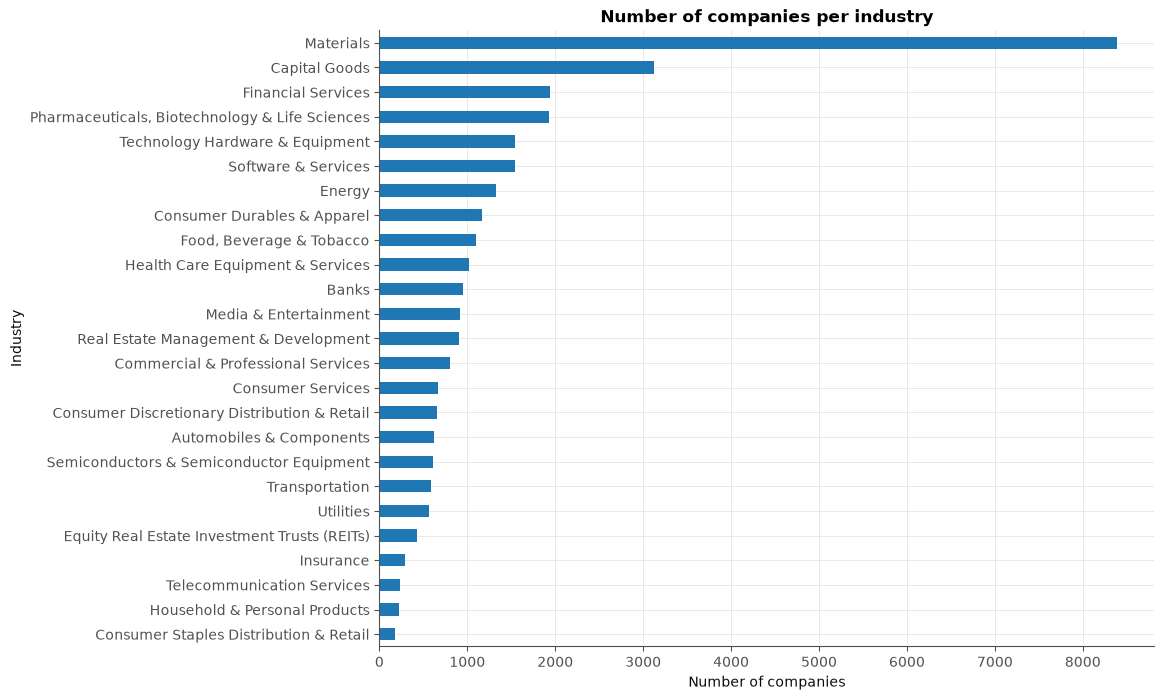

In [9]:
import matplotlib.pyplot as plt

class_counts = df["industry"].value_counts()
print(class_counts)

plt.figure(figsize=(10, 8))
class_counts.sort_values().plot(kind="barh")
plt.xlabel("Number of companies")
plt.ylabel("Industry")
plt.title("Number of companies per industry")
plt.show()

In [10]:
emb_counts = df.business_description_embedding.value_counts()
shared = emb_counts[emb_counts > 1]
print(f"{len(shared)} distinct vectors are shared by 2+ companies (together {shared.sum():,} rows)\n")

rows = []
for s, n in shared.head(8).items():
    labels = df.industry[df.business_description_embedding == s].value_counts()
    rows.append({"companies sharing this vector": n, "most common industry": labels.index[0],
                 "% with that industry": 100 * labels.iloc[0] / n, "distinct industries": len(labels)})
display(pd.DataFrame(rows).round(1))

# flag the two huge groups as "template" embeddings
TEMPLATE_STRINGS = set(shared[shared >= 100].index)
df["is_template"] = df.business_description_embedding.isin(TEMPLATE_STRINGS)
print(f"rows with a template embedding (vector shared by >= 100 companies): "
      f"{df.is_template.sum():,} = {df.is_template.mean()*100:.1f} % of the data")
print("their industries:", df.loc[df.is_template, "industry"].value_counts().head(3).to_dict())
print(f"share of ALL Materials companies that have a template embedding: "
      f"{df.is_template[df.industry == 'Materials'].mean()*100:.0f} %")

53 distinct vectors are shared by 2+ companies (together 4,631 rows)



,companies sharing this vector,most common industry,% with that industry,distinct industries
0,4359,Materials,99.7,9
1,116,Materials,99.1,2
2,19,Financial Services,100.0,1
3,9,Financial Services,100.0,1
4,9,Real Estate Management & Development,22.2,8
5,7,Equity Real Estate Investment Trusts (REITs),71.4,3
6,6,Equity Real Estate Investment Trusts (REITs),50.0,4
7,6,Materials,100.0,1


rows with a template embedding (vector shared by >= 100 companies): 4,475 = 14.1 % of the data
their industries: {'Materials': 4463, 'Financial Services': 2, 'Real Estate Management & Development': 2}
share of ALL Materials companies that have a template embedding: 53 %


### What we learned (Section 1)
* **One row = one company**: an `id`, its `industry` (the **target**, 25 classes) and its description embedding (the **features**). 31,706 companies, **no missing values**.
* The embedding is a text string that we parse into a **768-dimensional vector of length 1**. Values are small (std ≈ 0.036) and on the same scale in every dimension, so no standardisation is needed, and Euclidean distance ≡ cosine similarity.
* One id (13767) appears twice with the same label and slightly different embeddings — most likely two versions of the same description. Harmless (both end up in the training set).
* **The big surprise: 4,475 companies (14 %) do not have a real description embedding.** 4,359 of them share one single vector and another 116 share a second one, and almost all are labelled *Materials*. This looks like a **default/placeholder text** (e.g. a missing or boilerplate description) that was run through the embedding model. More than half of all Materials companies are in this group.

**Why this matters, and what we do about it**
* For a model it is a trivial rule: "this exact vector ⇒ Materials". It is correct 99.7 % of the time, so it inflates every score. We **keep** these rows (the private test set was presumably produced by the same pipeline, so the rule is genuinely useful there too), but we add the flag `is_template` and later **report performance on real descriptions separately**, so we know what the models actually learned from text.
* All 4,359 companies sit on one single point, which will distort PCA (Section 5).
* This is a good example of why we look at the raw data before modelling.

## 2. Train / validation split

### Questions to ask ourselves
* **Why split at all?** A model always looks good on the data it was trained on. The validation set plays the role of *new, unseen companies*, so its score estimates how the model will do on the private test set.
* **How big?** We keep the skeleton's choice: 90 % train, 10 % validation, `random_state=42` (so everyone gets the same split and results are reproducible).
* **Should the split be stratified** (keep class proportions identical in both parts)? The skeleton does not stratify. With ~3,000 validation rows the proportions should still be close — we check this in Section 4 instead of assuming it.

Rule we follow from now on: **the validation set is only used for the final evaluation.** Any choice we tune (regularisation strength, number of neighbours) is tuned on a separate slice of the training data, otherwise the validation score would be optimistically biased.

In [11]:
df_train, df_val = train_test_split(df, test_size=0.1, random_state=RANDOM_STATE)

# pick the rows of the parsed matrix that belong to each part (same order as the dataframes)
X_train = X_all[df.index.get_indexer(df_train.index)]
X_val   = X_all[df.index.get_indexer(df_val.index)]

print(f"train: {X_train.shape}   validation: {X_val.shape}")
print("duplicate company 13767 ends up in:",
      "train" if (df_train.id == 13767).any() else "", "validation" if (df_val.id == 13767).any() else "")

NameError: name 'X_all' is not defined

## 3. Label encoding

### Questions to ask ourselves
* **Why encode?** Models work with numbers. `LabelEncoder` maps each industry name to an integer 0…24 (alphabetically).
* **Does the integer imply an order?** No — "Banks = 1" is not "smaller" than "Utilities = 24". That is fine here because both classifiers treat the target as *categories*: logistic regression learns one weight vector per class, k-NN just votes. (If we used the label as an input *feature* we would need one-hot encoding instead.)
* **Fit on what?** We fit the encoder on the training labels, then check that every validation industry was seen in training — a class that never appears in training can never be predicted.

In [ ]:
le = LabelEncoder().fit(df_train.industry)

unseen = set(df_val.industry) - set(le.classes_)
print("industries in validation that are missing from training:", unseen if unseen else "none ✓")

y_train = le.transform(df_train.industry)
y_val   = le.transform(df_val.industry)
CLASSES = le.classes_
pd.DataFrame({"industry": CLASSES}).rename_axis("code")

industries in validation that are missing from training: none ✓


,industry
code,
0,Automobiles & Components
1,Banks
2,Capital Goods
3,Commercial & Professional Services
4,Consumer Discretionary Distribution & Retail
5,Consumer Durables & Apparel
6,Consumer Services
7,Consumer Staples Distribution & Retail
8,Energy


## 4. Class distribution — are some industries over- or under-represented?

### Questions to ask ourselves
* How many companies per industry? Is it roughly balanced or very skewed?
* What would a "dumb" model score that always predicts the biggest class? (This **baseline** tells us what a score is worth.)
* Do train and validation have similar proportions (we did not stratify)?
* What does imbalance mean for which **metric** we should trust?

In [ ]:
counts = pd.DataFrame({
    "train": df_train.industry.value_counts(),
    "validation": df_val.industry.value_counts(),
}).fillna(0).astype(int).sort_values("train", ascending=False)
counts["train %"] = 100 * counts.train / counts.train.sum()
counts["validation %"] = 100 * counts.validation / counts.validation.sum()
counts.round(2)

,train,validation,train %,validation %
industry,,,,
Materials,7604,790,26.65,24.91
Capital Goods,2805,322,9.83,10.15
"Pharmaceuticals, Biotechnology & Life Sciences",1742,183,6.10,5.77
Financial Services,1740,196,6.10,6.18
Technology Hardware & Equipment,1390,157,4.87,4.95
Software & Services,1384,153,4.85,4.82
Energy,1174,152,4.11,4.79
Consumer Durables & Apparel,1037,127,3.63,4.01
"Food, Beverage & Tobacco",956,138,3.35,4.35


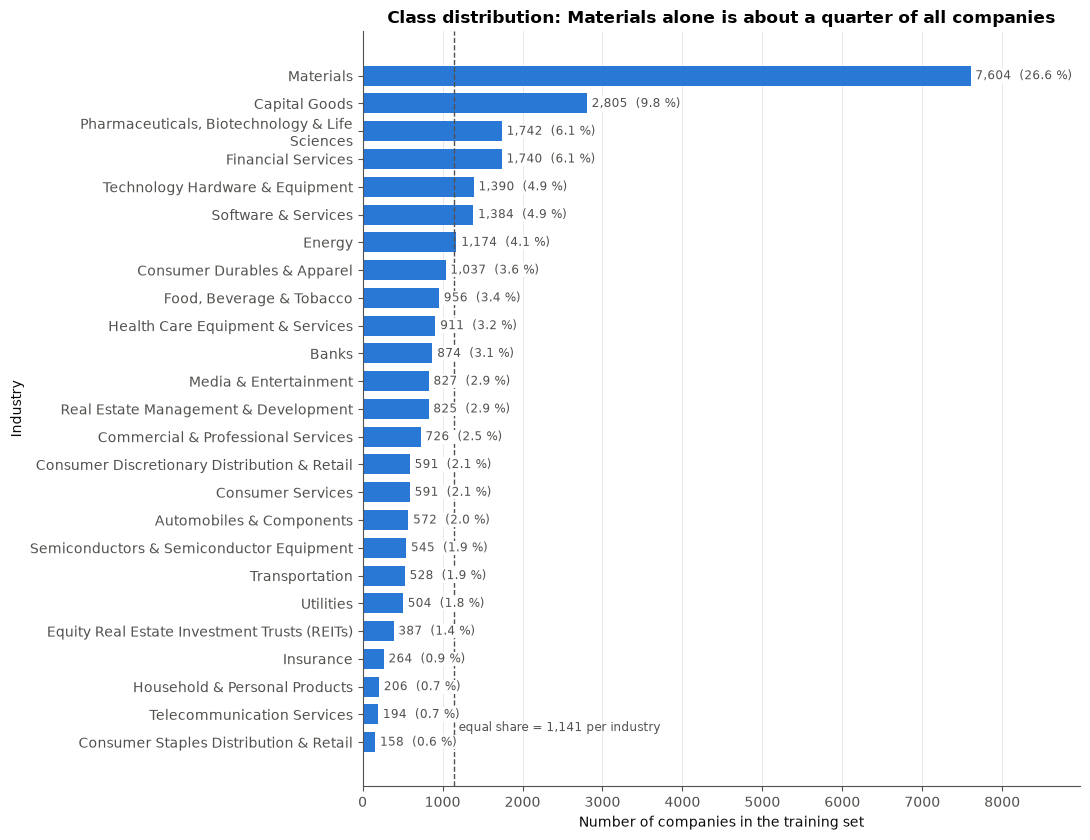

In [ ]:
fig, ax = plt.subplots(figsize=(11, 8.5))
order = counts.index[::-1]                       # largest bar on top
ax.barh([short(i, 45) for i in order], counts.loc[order, "train"], color=C_LR, height=0.72)
for yi, ind in enumerate(order):
    n, s = counts.loc[ind, "train"], counts.loc[ind, "train %"]
    ax.text(n + 60, yi, f"{n:,}  ({s:.1f} %)", va="center", fontsize=8.5, color=INK2,
            bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
equal = counts.train.sum() / len(counts)
ax.axvline(equal, color=INK2, ls="--", lw=1)
ax.text(equal + 60, 0.4, f"equal share = {equal:,.0f} per industry", fontsize=8.5, color=INK2)
ax.set_xlabel("Number of companies in the training set")
ax.set_ylabel("Industry")
ax.set_title("Class distribution: Materials alone is about a quarter of all companies")
ax.set_xlim(0, counts.train.max() * 1.18)
ax.grid(axis="y", visible=False)
plt.tight_layout()

In [ ]:
largest, smallest = counts.train.iloc[0], counts.train.iloc[-1]
print(f"largest / smallest class: {largest} / {smallest} = {largest/smallest:.0f}x")
print(f"top 3 industries hold {counts['train %'].iloc[:3].sum():.1f} % of companies")

majority = np.bincount(y_train).argmax()
base_pred = np.full_like(y_val, majority)
print(f"\nBaseline 'always predict {CLASSES[majority]}':")
print(f"  accuracy    = {accuracy_score(y_val, base_pred):.3f}")
print(f"  weighted F1 = {f1_score(y_val, base_pred, average='weighted'):.3f}")
print(f"  macro F1    = {f1_score(y_val, base_pred, average='macro'):.3f}")

max_gap = (counts["train %"] - counts["validation %"]).abs().max()
print(f"\nlargest difference between train % and validation % of any class: {max_gap:.2f} percentage points")

largest / smallest class: 7604 / 158 = 48x
top 3 industries hold 42.6 % of companies

Baseline 'always predict Materials':
  accuracy    = 0.249
  weighted F1 = 0.099
  macro F1    = 0.016

largest difference between train % and validation % of any class: 1.73 percentage points


### What we learned (Section 4)
* **Strongly imbalanced.** Materials alone is 26.6 % of companies, the top three industries hold 42.6 %, and the largest class is **48× the smallest** (7,604 Materials vs. 158 Consumer Staples Distribution & Retail). 18 of the 25 industries are below the "equal share" line. (Remember that about half of Materials are the template rows from Section 1.)
* **Under-represented:** Consumer Staples Distribution & Retail, Telecommunication Services, Household & Personal Products and Insurance each have under 1 % of the data — the models will see only ~150–260 examples of them.
* **Baseline:** always predicting *Materials* already gives **24.9 % accuracy**, but only 0.10 weighted F1 and 0.016 macro F1. So accuracy alone flatters a model that ignores small classes; we will always report **weighted and macro F1** next to accuracy.
* Train and validation proportions differ by at most 1.7 percentage points, so not stratifying the split is acceptable. Still, the smallest classes have only ~20 validation companies, so their per-class scores will be noisy (one company = 5 percentage points).

## 5. PCA — is there signal in the embeddings?

We cannot look at 768 dimensions. **Principal Component Analysis** finds the few directions along which the data varies most, so we can project onto 2 of them and plot.

### The maths behind PCA
Let $X \in \mathbb{R}^{n\times d}$ be the data ($n$ companies, $d=768$).

1. **Centre** the data: $X_c = X - \bar{x}$ (subtract the mean vector from every row).
2. **Covariance matrix**: $\Sigma = \frac{1}{n-1} X_c^\top X_c \in \mathbb{R}^{d\times d}$. Entry $\Sigma_{jk}$ says how dimensions $j$ and $k$ vary together.
3. **Eigen-decomposition**: $\Sigma v_k = \lambda_k v_k$, sorted $\lambda_1 \ge \lambda_2 \ge \dots$
   * $v_1$ is the unit direction along which the projected data has the **largest variance**; that variance is $\lambda_1$. $v_2$ is the best direction *orthogonal* to $v_1$, and so on.
   * Why eigenvectors? Maximise $\operatorname{Var}(X_c v) = v^\top \Sigma v$ subject to $\lVert v\rVert=1$. With a Lagrange multiplier: $\nabla_v\big(v^\top\Sigma v - \lambda(v^\top v - 1)\big)=0 \Rightarrow \Sigma v = \lambda v$.
4. **Project**: $Z = X_c V_k$ with $V_k=[v_1,\dots,v_k]$. Row $i$ of $Z$ are the coordinates of company $i$ on the first $k$ principal components.
5. **Explained variance ratio** of component $k$: $\lambda_k / \sum_j \lambda_j$ — the share of total variance it captures.

(scikit-learn computes the same thing through the singular value decomposition $X_c = U S V^\top$, with $\lambda_k = s_k^2/(n-1)$, which is numerically more stable.)

### Questions to ask ourselves
* How much of the total variance do 2 components keep? If it is small, a 2-D plot is a **lossy** view: overlap in 2-D does *not* prove the classes overlap in 768-D.
* In the 2-D picture, do companies of the same industry gather in the same region?
* Which industries look separable, which overlap?
* Beyond the picture: how much classification signal sits in the first few components versus the rest?

PCA is fitted on the **training data only** (the validation data is just projected), so no information leaks from validation.

PC1 explains 19.3 %, PC2 6.1 %  ->  together 25.4 % of the variance
first  10 components: 47.3 %
first  50 components: 72.2 %
first 100 components: 83.7 %
components needed for 50 % of the variance: 12

for comparison, PCA WITHOUT the template rows: PC1 7.5 %, PC2 5.6 %


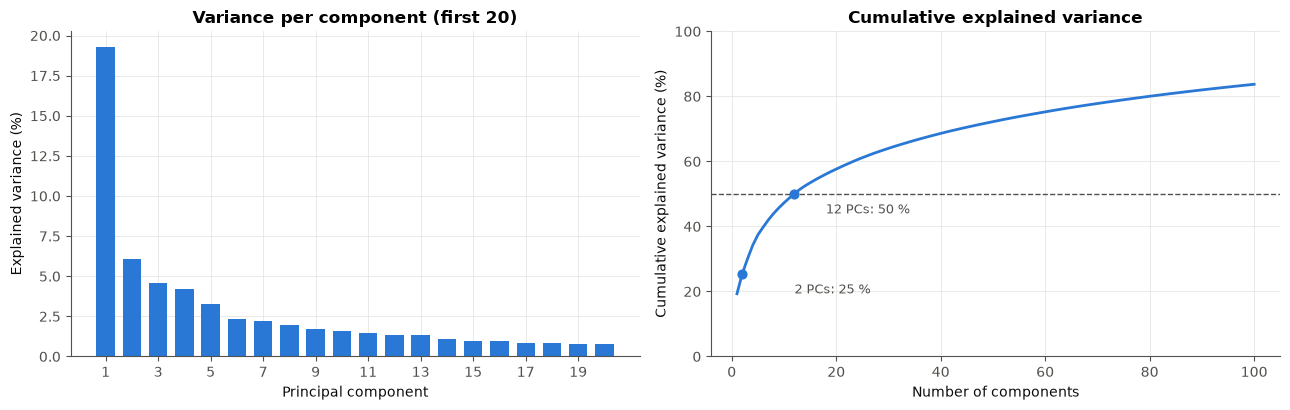

In [ ]:
pca = PCA(n_components=100, random_state=RANDOM_STATE).fit(X_train)
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
print(f"PC1 explains {evr[0]*100:.1f} %, PC2 {evr[1]*100:.1f} %  ->  together {cum[1]*100:.1f} % of the variance")
for k in (10, 50, 100):
    print(f"first {k:>3} components: {cum[k-1]*100:.1f} %")
k50 = np.argmax(cum >= 0.5) + 1
print(f"components needed for 50 % of the variance: {k50}")

real_tr = ~df_train.is_template.values
evr_real = PCA(n_components=5, random_state=RANDOM_STATE).fit(X_train[real_tr]).explained_variance_ratio_
print(f"\nfor comparison, PCA WITHOUT the template rows: PC1 {evr_real[0]*100:.1f} %, PC2 {evr_real[1]*100:.1f} %")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
a1.bar(np.arange(1, 21), evr[:20] * 100, color=C_LR, width=0.7)
a1.set_xlabel("Principal component")
a1.set_ylabel("Explained variance (%)")
a1.set_title("Variance per component (first 20)")
a1.set_xticks(range(1, 21, 2))
a2.plot(np.arange(1, 101), cum * 100, color=C_LR, lw=2)
a2.axhline(50, color=INK2, ls="--", lw=1)
a2.scatter([2, k50], [cum[1] * 100, cum[k50 - 1] * 100], color=C_LR, s=40, zorder=3)
a2.annotate(f"2 PCs: {cum[1]*100:.0f} %", (2, cum[1] * 100), xytext=(12, cum[1] * 100 - 6), fontsize=9, color=INK2)
a2.annotate(f"{k50} PCs: 50 %", (k50, 50), xytext=(k50 + 6, 44), fontsize=9, color=INK2)
a2.set_xlabel("Number of components")
a2.set_ylabel("Cumulative explained variance (%)")
a2.set_title("Cumulative explained variance")
a2.set_ylim(0, 100)
plt.tight_layout()

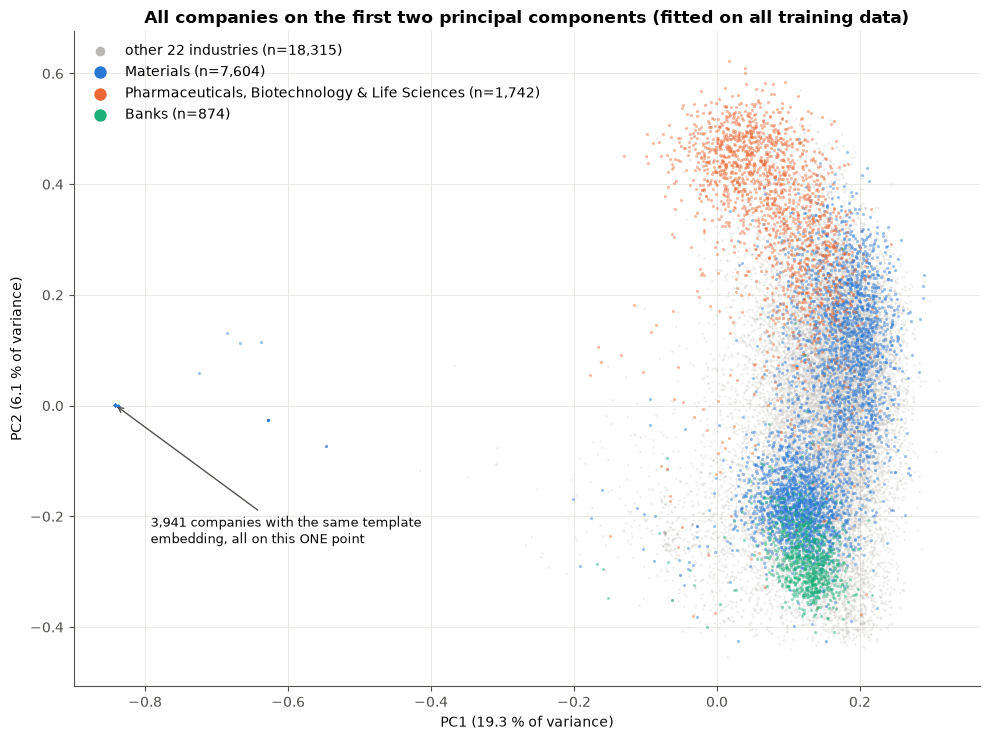

In [ ]:
Z_train = pca.transform(X_train)
Z_val   = pca.transform(X_val)
ind_train = df_train.industry.values

HIGHLIGHT = ["Materials", "Pharmaceuticals, Biotechnology & Life Sciences", "Banks"]
fig, ax = plt.subplots(figsize=(10, 7.5))
other = ~np.isin(ind_train, HIGHLIGHT)
ax.scatter(Z_train[other, 0], Z_train[other, 1], s=3, c=C_GREY, alpha=0.25, lw=0,
           label=f"other 22 industries (n={other.sum():,})", rasterized=True)
for ind, col in zip(HIGHLIGHT, [C_LR, C_KNN, C_ACCENT]):
    m = ind_train == ind
    ax.scatter(Z_train[m, 0], Z_train[m, 1], s=5, c=col, alpha=0.45, lw=0,
               label=f"{ind} (n={m.sum():,})", rasterized=True)
ax.set_xlabel(f"PC1 ({evr[0]*100:.1f} % of variance)")
ax.set_ylabel(f"PC2 ({evr[1]*100:.1f} % of variance)")
ax.set_title("All companies on the first two principal components (fitted on all training data)")
leg = ax.legend(loc="upper left", markerscale=4, frameon=False)
for h in leg.legend_handles: h.set_alpha(1)
big = (df_train.business_description_embedding == emb_counts.index[0]).values
tz = Z_train[big][0]
ax.annotate(f"{big.sum():,} companies with the same template\nembedding, all on this ONE point",
            xy=(tz[0], tz[1]), xytext=(tz[0] + 0.05, tz[1] - 0.25), fontsize=9, color=INK,
            arrowprops=dict(arrowstyle="->", color=INK2))
plt.tight_layout()

The template rows from Section 1 show up exactly as feared: thousands of identical points sit on **one dot** far to the left. PC1 is mostly "template vs. everything else" (it explains 19 % of variance with the template rows, but only ~7.5 % without them) and squeezes the real structure into the right edge of the plot.

For **visualisation** we therefore fit a second PCA on the real descriptions only. (The classifiers still get the full data.)

With 25 classes, one scatter plot with 25 colours would be unreadable (no one can tell 25 hues apart). We first highlight three contrasting industries, then use **small multiples**: the same grey cloud of all companies in every panel, with one industry highlighted per panel. The cross marks that industry's centre (mean position).

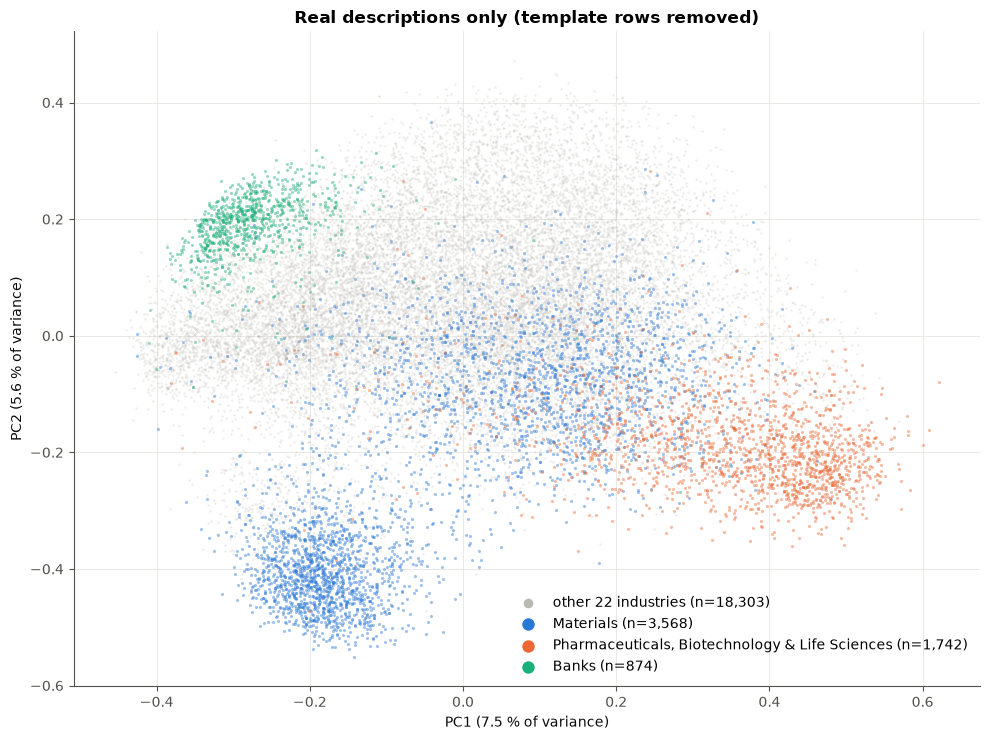

In [ ]:
pca_vis = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_train[real_tr])
V = pca_vis.transform(X_train[real_tr])
ind_real = ind_train[real_tr]
ev = pca_vis.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(10, 7.5))
other = ~np.isin(ind_real, HIGHLIGHT)
ax.scatter(V[other, 0], V[other, 1], s=3, c=C_GREY, alpha=0.25, lw=0,
           label=f"other 22 industries (n={other.sum():,})", rasterized=True)
for ind, col in zip(HIGHLIGHT, [C_LR, C_KNN, C_ACCENT]):
    m = ind_real == ind
    ax.scatter(V[m, 0], V[m, 1], s=5, c=col, alpha=0.45, lw=0, label=f"{ind} (n={m.sum():,})", rasterized=True)
ax.set_xlabel(f"PC1 ({ev[0]:.1f} % of variance)")
ax.set_ylabel(f"PC2 ({ev[1]:.1f} % of variance)")
ax.set_title("Real descriptions only (template rows removed)")
leg = ax.legend(loc="best", markerscale=4, frameon=False)
for h in leg.legend_handles: h.set_alpha(1)
plt.tight_layout()

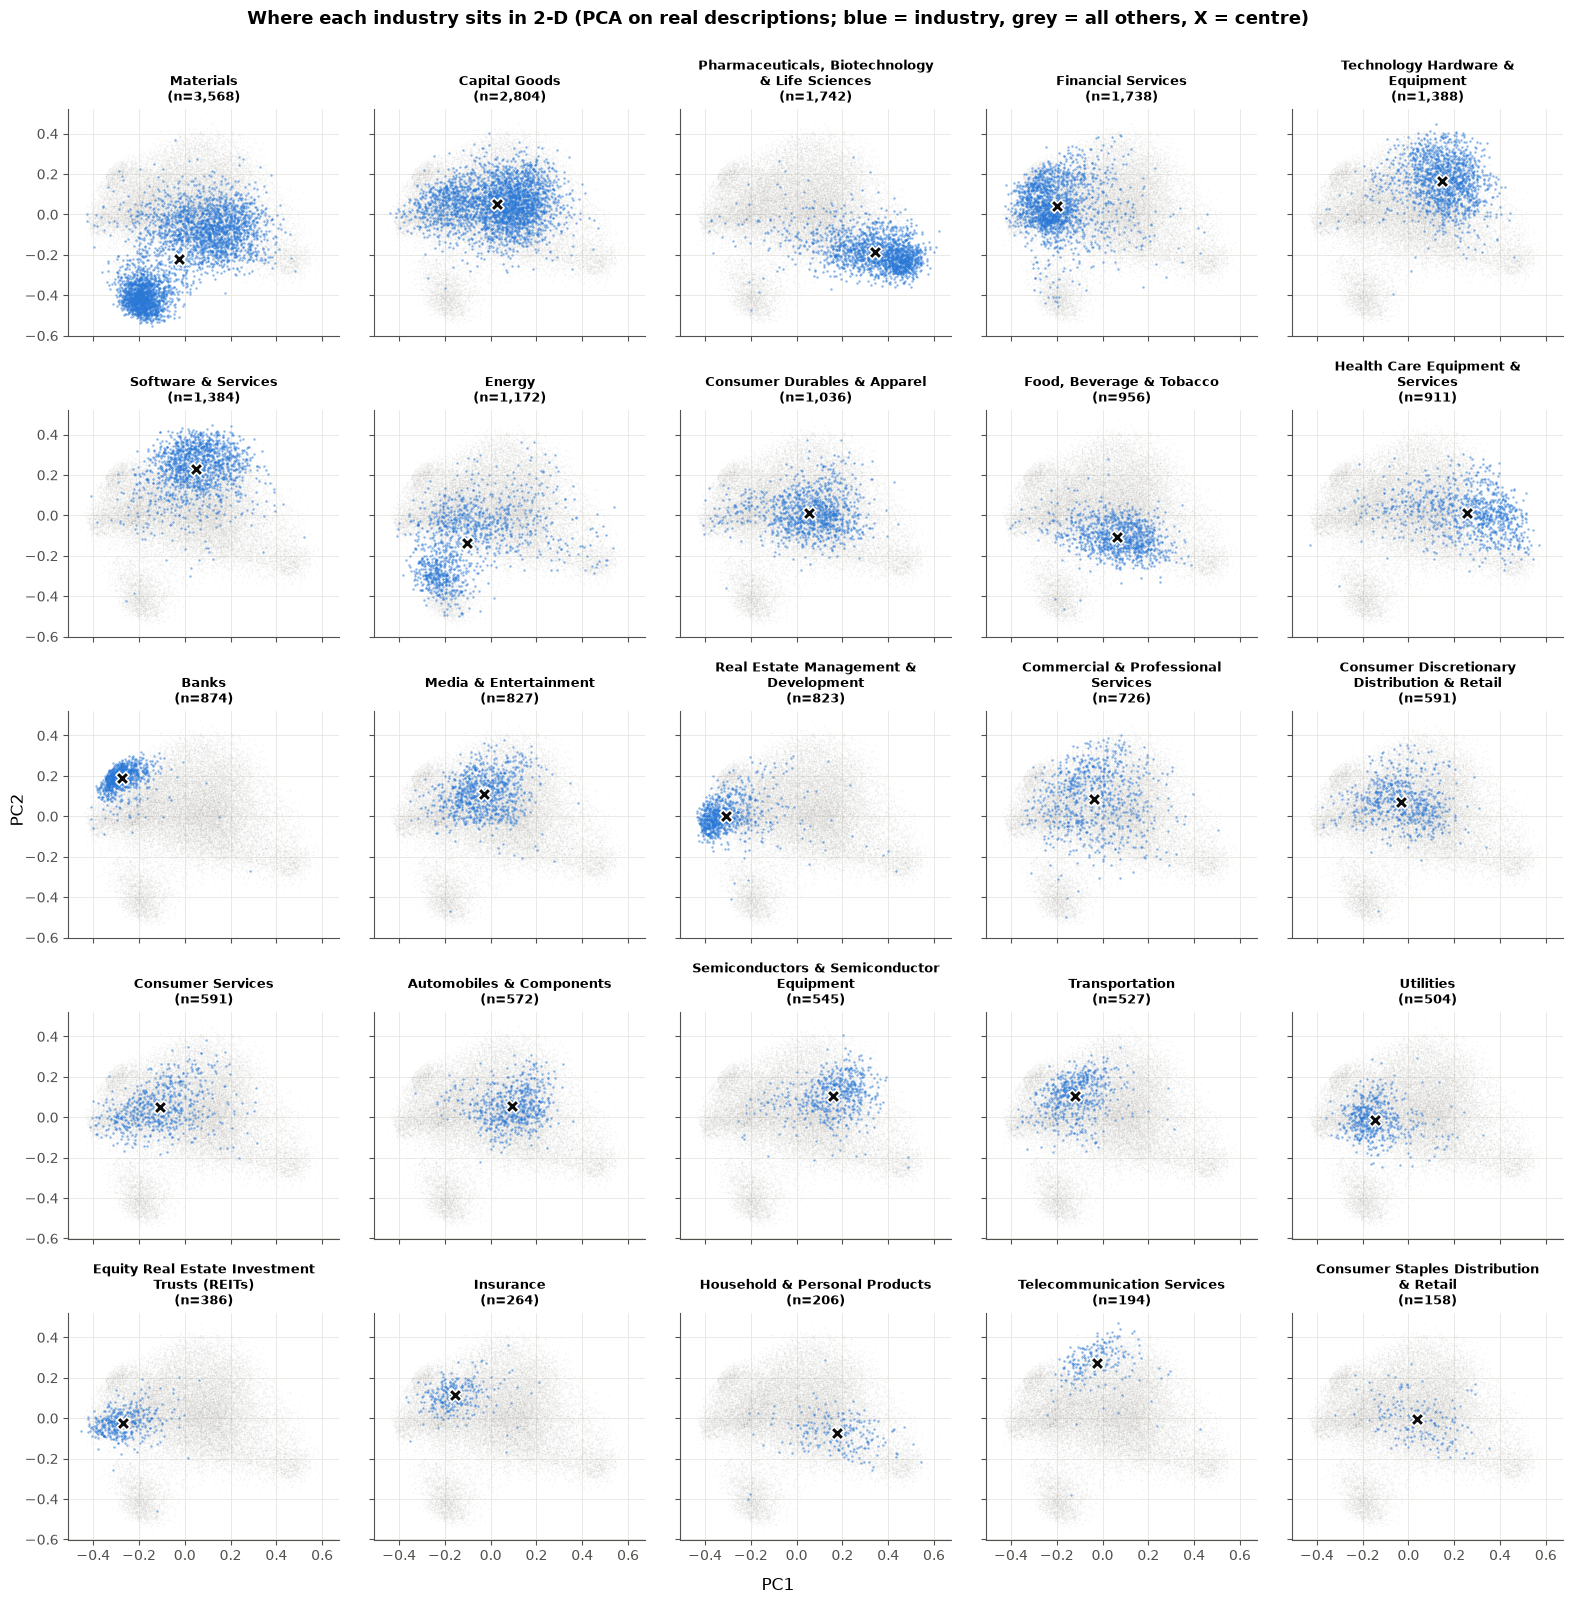

In [ ]:
fig, axes = plt.subplots(5, 5, figsize=(16, 16), sharex=True, sharey=True)
for ax, ind in zip(axes.flat, counts.index):
    m = ind_real == ind
    ax.scatter(V[~m, 0], V[~m, 1], s=1, c=C_GREY, alpha=0.12, lw=0, rasterized=True)
    ax.scatter(V[m, 0], V[m, 1], s=3, c=C_LR, alpha=0.55, lw=0, rasterized=True)
    cx, cy = V[m, 0].mean(), V[m, 1].mean()
    ax.scatter([cx], [cy], marker="X", s=90, c=INK, edgecolors="white", linewidths=1.2, zorder=3)
    ax.set_title(f"{short(ind, 30)}\n(n={m.sum():,})", fontsize=9)
fig.supxlabel("PC1", fontsize=12)
fig.supylabel("PC2", fontsize=12)
fig.suptitle("Where each industry sits in 2-D (PCA on real descriptions; blue = industry, grey = all others, X = centre)",
             fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout()

### How much signal is in the first $k$ components?
The 2-D picture only shows a quarter of the variance. A more honest test of "is there signal?" is to train a simple classifier (logistic regression) on the first $k$ principal components and watch validation accuracy as $k$ grows. If accuracy climbs far above the 26 % majority baseline, the embeddings clearly encode the industry.

,components,val accuracy,variance kept %,fit s
0,2,0.346,25.398,0.723
1,5,0.554,37.408,0.806
2,10,0.659,47.256,0.838
3,20,0.722,57.637,0.884
4,50,0.754,72.219,0.926
5,100,0.764,83.714,1.149
6,768,0.773,100.000,4.023


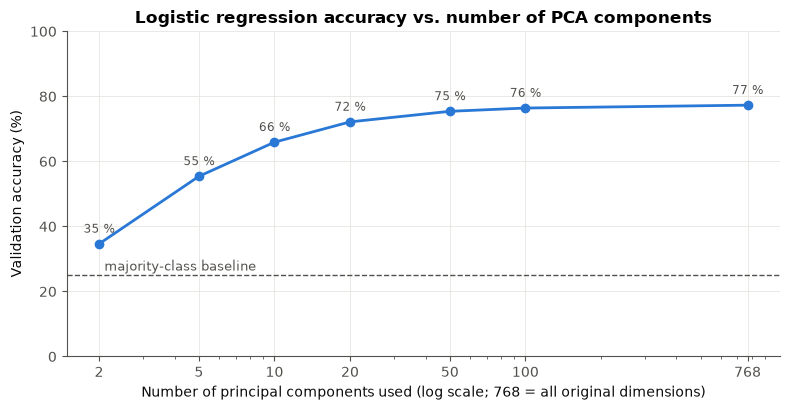

In [ ]:
rows = []
for k in [2, 5, 10, 20, 50, 100]:
    t0 = time.time()
    m = LogisticRegression(max_iter=3000).fit(Z_train[:, :k], y_train)
    rows.append({"components": k, "val accuracy": accuracy_score(y_val, m.predict(Z_val[:, :k])),
                 "variance kept %": cum[k - 1] * 100, "fit s": time.time() - t0})
t0 = time.time()
m = LogisticRegression(max_iter=3000).fit(X_train, y_train)
rows.append({"components": 768, "val accuracy": accuracy_score(y_val, m.predict(X_val)),
             "variance kept %": 100.0, "fit s": time.time() - t0})
pc_curve = pd.DataFrame(rows)
display(pc_curve.round(3))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(pc_curve["components"], pc_curve["val accuracy"] * 100, "-o", color=C_LR, lw=2, ms=6)
ax.axhline(accuracy_score(y_val, base_pred) * 100, color=INK2, ls="--", lw=1)
ax.text(2.1, accuracy_score(y_val, base_pred) * 100 + 1.5, "majority-class baseline", fontsize=9, color=INK2)
for _, r in pc_curve.iterrows():
    ax.annotate(f"{r['val accuracy']*100:.0f} %", (r.components, r["val accuracy"] * 100),
                xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8.5, color=INK2)
ax.set_xscale("log")
ax.set_xticks(pc_curve["components"]); ax.set_xticklabels(pc_curve["components"])
ax.set_xlabel("Number of principal components used (log scale; 768 = all original dimensions)")
ax.set_ylabel("Validation accuracy (%)")
ax.set_title("Logistic regression accuracy vs. number of PCA components")
ax.set_ylim(0, 100)
plt.tight_layout()

### What we learned (Section 5): is there signal that allows industry classification?
* **The variance is spread over many directions.** Two components keep only 25 % of the variance (and much of PC1 is the template artifact); 12 components are needed for 50 % and 100 components for 84 %. A 2-D plot is therefore a strongly compressed view: overlap in 2-D does **not** mean overlap in 768-D.
* **Even so, the 2-D picture shows clear structure** (real-description plot):
  * **Separate, compact regions:** Banks (top-left), Real Estate Management and REITs (left), Pharma/Biotech (right), and a dense **Materials sub-cluster** at the bottom (probably mining/mineral exploration companies, whose descriptions are very similar; part of Energy — exploration companies — sits there too).
  * **Broad, overlapping clouds in the middle:** Capital Goods, Consumer Durables, Commercial & Professional Services, Consumer Services, Media, Automobiles. These are the industries we expect to be confused.
  * **Neighbourhoods that make economic sense:** finance-related industries (Banks, Financial Services, Insurance, Real Estate) are on the left; technology (Software, Tech Hardware, Semiconductors, Telecom) on the upper right; health (Pharma, Health Care Equipment, Household & Personal Products) on the right. The embedding space mirrors sector structure.
  * **Several industries are multi-modal** (Materials, Energy) — a single "centre" describes them badly in 2-D. This is a point in favour of flexible methods like k-NN, although in the full 768 dimensions a linear model may still separate them.
* **Quantitatively:** logistic regression on only 2 components already beats the baseline (35 % vs 25 %), 10 components give 66 %, 50 give 75 %, and all 768 dimensions give 77 %. Most of the useful signal is in the first ~50 directions, but the remaining ones still add a little.
* **Conclusion: yes, there is strong signal in the embeddings for industry classification**, with a clear expectation of which industries will be easy (compact, separate clusters) and which will be hard (central, overlapping ones).

## 6. Two classifiers: logistic regression and k-nearest neighbours

### Logistic regression (multinomial / softmax)
For each class $c$ the model learns a weight vector $w_c\in\mathbb{R}^{768}$ and a bias $b_c$. For a company $x$:
$$z_c = w_c^\top x + b_c, \qquad P(y=c\mid x) = \frac{e^{z_c}}{\sum_{j=1}^{25} e^{z_j}} \quad(\text{softmax}).$$
The weights are chosen to minimise the **cross-entropy** (negative log-likelihood) plus an **L2 penalty**:
$$\mathcal{L}(W) = -\sum_{i=1}^{n}\log P(y_i\mid x_i) \;+\; \frac{1}{2C}\lVert W\rVert^2 .$$
* The first term rewards giving high probability to the true industry.
* The penalty keeps weights small to avoid overfitting; **$C$ is the inverse regularisation strength** (large $C$ = weak penalty = more flexible model).
* Decision boundaries between two classes are where $z_a = z_b$, i.e. **hyperplanes** — the model is *linear*. It works well if industries occupy different "directions" of the embedding space.
* Bonus: it outputs probabilities, which we will need for the confidence task.

### k-nearest neighbours (k-NN)
No real training — the model memorises all training points. To classify $x$:
1. compute the distance from $x$ to every training company (Euclidean, which here equals cosine — see Section 1),
2. take the $k$ closest,
3. **vote**: `uniform` = each neighbour one vote; `distance` = each vote weighted by $1/\text{distance}$, so very close neighbours count more.

$P(y=c\mid x) \approx$ (weighted) share of the $k$ neighbours in class $c$. k-NN can draw **any** shape of boundary (non-linear), but it is sensitive to class imbalance (big classes are more likely to be among the neighbours) and slow at prediction time (distance to every training point).

### Questions to ask ourselves
* Which hyper-parameters matter? $C$ for logistic regression, $k$ and the weighting for k-NN.
* How do we pick them **without peeking at the validation set**? → hold out 15 % of the *training* data as a "tuning" set.
* How long does each model take? (The task requires < 45 min on a laptop.)

In [ ]:
X_fit, X_tune, y_fit, y_tune = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE)
print(f"fit part: {X_fit.shape[0]:,} rows   tuning part: {X_tune.shape[0]:,} rows")

lr_rows = []
for C in [0.1, 1, 10]:
    t0 = time.time()
    m = LogisticRegression(C=C, max_iter=3000).fit(X_fit, y_fit)
    p = m.predict(X_tune)
    lr_rows.append({"C": C, "accuracy": accuracy_score(y_tune, p),
                    "weighted F1": f1_score(y_tune, p, average="weighted"), "fit s": time.time() - t0})
lr_tuning = pd.DataFrame(lr_rows)
display(lr_tuning.round(4))

knn_rows = []
for k in [1, 5, 10, 15, 25, 40, 60]:
    for w in ["uniform", "distance"]:
        p = KNeighborsClassifier(n_neighbors=k, weights=w, n_jobs=-1).fit(X_fit, y_fit).predict(X_tune)
        knn_rows.append({"k": k, "weights": w, "accuracy": accuracy_score(y_tune, p),
                         "weighted F1": f1_score(y_tune, p, average="weighted")})
knn_tuning = pd.DataFrame(knn_rows)
display(knn_tuning.pivot(index="k", columns="weights", values="weighted F1").round(4))

fit part: 24,254 rows   tuning part: 4,281 rows


,C,accuracy,weighted F1,fit s
0,0.1,0.7302,0.7117,1.9846
1,1.0,0.7800,0.7756,2.7137
2,10.0,0.7814,0.7786,6.7538


weights,distance,uniform
k,,
1,0.7197,0.7197
5,0.7634,0.7634
10,0.7739,0.7742
15,0.7712,0.7709
25,0.7670,0.7658
40,0.7626,0.7629
60,0.7565,0.7557


chosen: logistic regression C = 10.0;  k-NN k = 10, weights = 'uniform'


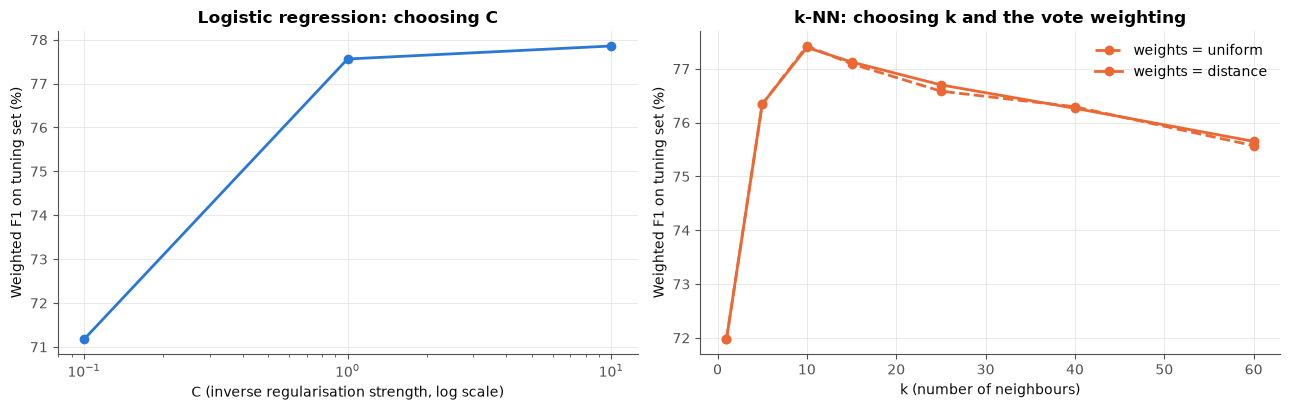

In [ ]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
a1.plot(lr_tuning.C, lr_tuning["weighted F1"] * 100, "-o", color=C_LR, lw=2)
a1.set_xscale("log")
a1.set_xlabel("C (inverse regularisation strength, log scale)")
a1.set_ylabel("Weighted F1 on tuning set (%)")
a1.set_title("Logistic regression: choosing C")
for w, ls in [("uniform", "--"), ("distance", "-")]:
    d = knn_tuning[knn_tuning.weights == w]
    a2.plot(d.k, d["weighted F1"] * 100, ls, marker="o", color=C_KNN, lw=2, label=f"weights = {w}")
a2.set_xlabel("k (number of neighbours)")
a2.set_ylabel("Weighted F1 on tuning set (%)")
a2.set_title("k-NN: choosing k and the vote weighting")
a2.legend(frameon=False)
plt.tight_layout()

best_C = lr_tuning.loc[lr_tuning["weighted F1"].idxmax(), "C"]
best = knn_tuning.loc[knn_tuning["weighted F1"].idxmax()]
best_k, best_w = int(best.k), best.weights
print(f"chosen: logistic regression C = {best_C};  k-NN k = {best_k}, weights = '{best_w}'")

Now we refit both models with the chosen settings on the **full** training set and predict the validation set once.

In [ ]:
t0 = time.time()
lr = LogisticRegression(C=best_C, max_iter=3000).fit(X_train, y_train)
t_lr = time.time() - t0
t0 = time.time()
knn = KNeighborsClassifier(n_neighbors=best_k, weights=best_w, n_jobs=-1).fit(X_train, y_train)
pred_knn = knn.predict(X_val)
t_knn = time.time() - t0
pred_lr = lr.predict(X_val)
print(f"logistic regression: fit {t_lr:.1f} s    k-NN: fit + predict {t_knn:.1f} s")

logistic regression: fit 8.0 s    k-NN: fit + predict 0.9 s


## 7. How good are the models?

### The metrics
For one class $c$, count on the validation set: **TP** (predicted $c$, truly $c$), **FP** (predicted $c$, truly something else), **FN** (truly $c$, predicted something else).

* **Precision** $= \frac{TP}{TP+FP}$ — "when the model says *Banks*, how often is it right?"
* **Recall** $= \frac{TP}{TP+FN}$ — "of all real banks, how many did the model find?"
* **F1** $= 2\cdot\frac{\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$ — the harmonic mean; it is only high if *both* are high.
* **Accuracy** $= \frac{\#\text{correct}}{n}$ over all classes.

Averaging F1 over 25 classes:
* **macro F1** $= \frac{1}{25}\sum_c F1_c$ — every industry counts equally, so small industries matter as much as Materials.
* **weighted F1** $= \sum_c \frac{n_c}{n} F1_c$ — weighted by class size, so it is dominated by the large classes (this is the one used in the bonus score).

With strong imbalance, comparing **weighted vs. macro** tells us whether the model is good everywhere or only on the big classes.

### Questions to ask ourselves
* How far above the 26 % baseline are we?
* Which model is better, and on which metric?
* Is the gap between weighted and macro F1 large (= small classes are weak)?

In [ ]:
def scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "weighted F1": f1_score(y_true, y_pred, average="weighted"),
            "macro F1": f1_score(y_true, y_pred, average="macro")}

summary = pd.DataFrame({
    "majority baseline": scores(y_val, base_pred),
    f"logistic regression (C={best_C})": scores(y_val, pred_lr),
    f"k-NN (k={best_k}, {best_w})": scores(y_val, pred_knn),
}).T
summary.round(3)

,accuracy,weighted F1,macro F1
majority baseline,0.249,0.099,0.016
logistic regression (C=10.0),0.776,0.773,0.713
"k-NN (k=10, uniform)",0.772,0.767,0.695


How much of this comes from the "free" template rows? We split the validation set into companies with a template embedding and companies with a real description:

In [ ]:
tmpl_val = df_val.is_template.values
split = {}
for name, pred in [("logistic regression", pred_lr), ("k-NN", pred_knn)]:
    for part, m in [("template embedding", tmpl_val), ("real description", ~tmpl_val)]:
        split[(name, part)] = {"companies": int(m.sum()),
                               "accuracy": accuracy_score(y_val[m], pred[m]),
                               "weighted F1": f1_score(y_val[m], pred[m], average="weighted")}
pd.DataFrame(split).T.round(3)

companies  accuracy  weighted F1
logistic regression template embedding      427.0     1.000        1.000
                    real description       2744.0     0.741        0.738
k-NN                template embedding      427.0     1.000        1.000
                    real description       2744.0     0.736        0.731

### Interpretation (overall scores)
* Both models are **about 3× better than the baseline**: ~77 % accuracy vs. 25 %, and weighted F1 0.77 vs. 0.10. The embeddings clearly carry the industry.
* **Logistic regression is slightly better on every metric** (accuracy 0.777 vs 0.772, weighted F1 0.774 vs 0.767, macro F1 0.714 vs 0.695). Section 8 tests whether that small gap is real.
* **Weighted F1 is ~6 points above macro F1** for both models: large classes are predicted better on average than small ones. Section 7's per-industry view shows this is driven by a few weak classes rather than a smooth size effect.
* **Honest number:** the ~13 % of validation companies with a template embedding are always right (they are trivially Materials). On **real descriptions accuracy is ≈ 74 %** — that is what the models learned from the text.
* Tuning picked a weak penalty for logistic regression ($C=10$: with 28k examples and 768 features there is enough data to support many weights) and $k=10$ for k-NN (uniform and distance weighting are practically identical). $k=1$ is clearly worst — a single neighbour is too noisy — and large $k$ slowly drifts toward the big classes.
* Is it "good"? For 25 fine-grained, partly overlapping industries, ~77 % is solid, and the remaining errors are mostly *plausible* (next sections).

### Per-industry performance — do errors correlate with class size?

In [ ]:
p_lr, r_lr, f_lr, sup = precision_recall_fscore_support(y_val, pred_lr, labels=range(len(CLASSES)), zero_division=0)
p_kn, r_kn, f_kn, _   = precision_recall_fscore_support(y_val, pred_knn, labels=range(len(CLASSES)), zero_division=0)
per_class = pd.DataFrame({
    "train n": np.bincount(y_train, minlength=len(CLASSES)), "val n": sup,
    "LR precision": p_lr, "LR recall": r_lr, "LR F1": f_lr,
    "kNN precision": p_kn, "kNN recall": r_kn, "kNN F1": f_kn,
}, index=CLASSES).sort_values("LR F1", ascending=False)
per_class.round(2)

,train n,val n,LR precision,LR recall,LR F1,kNN precision,kNN recall,kNN F1
Banks,874,74,0.99,0.95,0.97,0.76,0.96,0.85
Materials,7604,790,0.91,0.96,0.93,0.92,0.95,0.94
"Food, Beverage & Tobacco",956,138,0.85,0.86,0.85,0.85,0.87,0.86
Transportation,528,57,0.82,0.82,0.82,0.81,0.77,0.79
"Pharmaceuticals, Biotechnology & Life Sciences",1742,183,0.80,0.85,0.82,0.80,0.89,0.84
Financial Services,1740,196,0.78,0.81,0.79,0.75,0.74,0.75
Equity Real Estate Investment Trusts (REITs),387,45,0.76,0.82,0.79,0.75,0.73,0.74
Insurance,264,23,0.78,0.78,0.78,0.82,0.78,0.80
Utilities,504,65,0.85,0.71,0.77,0.82,0.75,0.78
Health Care Equipment & Services,911,103,0.75,0.78,0.77,0.77,0.79,0.78


Spearman rank correlation, class size vs F1:  LR rho = 0.17 (p = 0.415)   kNN rho = 0.18 (p = 0.381)


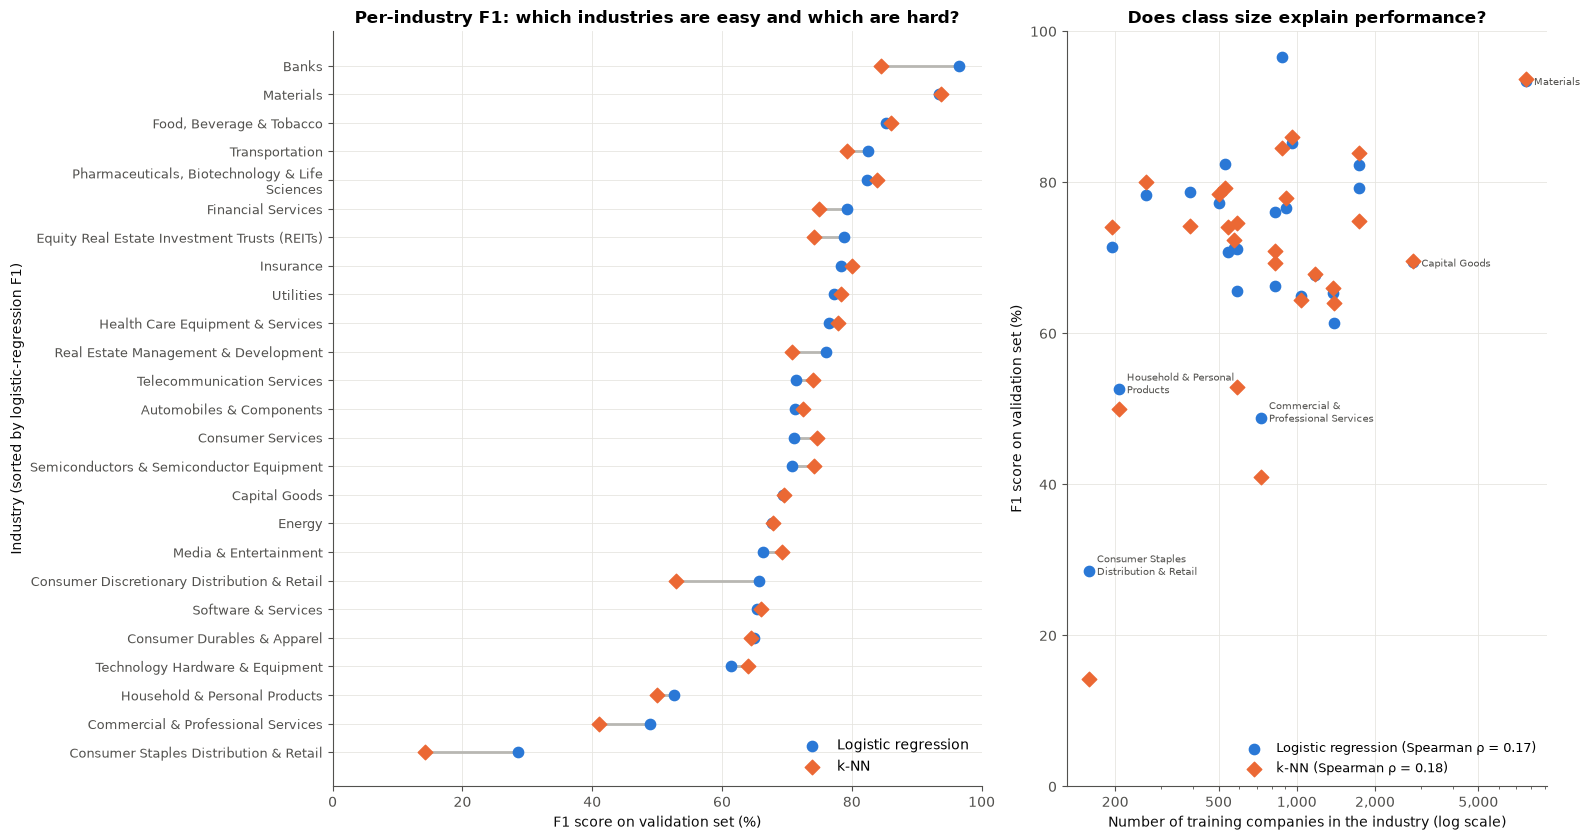

In [ ]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 8.5), gridspec_kw={"width_ratios": [1.35, 1]})

order = per_class.index[::-1]
yy = np.arange(len(order))
a1.hlines(yy, per_class.loc[order, ["LR F1", "kNN F1"]].min(axis=1) * 100,
          per_class.loc[order, ["LR F1", "kNN F1"]].max(axis=1) * 100, color=C_GREY, lw=2)
a1.scatter(per_class.loc[order, "LR F1"] * 100, yy, color=C_LR, s=55, zorder=3, label="Logistic regression")
a1.scatter(per_class.loc[order, "kNN F1"] * 100, yy, color=C_KNN, s=55, zorder=3, marker="D", label="k-NN")
a1.set_yticks(yy); a1.set_yticklabels([short(i, 45) for i in order], fontsize=9)
a1.set_xlabel("F1 score on validation set (%)")
a1.set_ylabel("Industry (sorted by logistic-regression F1)")
a1.set_title("Per-industry F1: which industries are easy and which are hard?")
a1.set_xlim(0, 100)
a1.legend(frameon=False, loc="lower right")

rho_lr, p_rho_lr = stats.spearmanr(per_class["train n"], per_class["LR F1"])
rho_kn, p_rho_kn = stats.spearmanr(per_class["train n"], per_class["kNN F1"])
a2.scatter(per_class["train n"], per_class["LR F1"] * 100, color=C_LR, s=55, label=f"Logistic regression (Spearman ρ = {rho_lr:.2f})")
a2.scatter(per_class["train n"], per_class["kNN F1"] * 100, color=C_KNN, s=55, marker="D", label=f"k-NN (Spearman ρ = {rho_kn:.2f})")
for ind in per_class.index:
    if per_class.loc[ind, "LR F1"] < 0.55 or per_class.loc[ind, "train n"] > 2500:
        a2.annotate(short(ind, 22), (per_class.loc[ind, "train n"], per_class.loc[ind, "LR F1"] * 100),
                    xytext=(6, -3), textcoords="offset points", fontsize=7.5, color=INK2)
a2.set_xscale("log")
a2.set_xticks([200, 500, 1000, 2000, 5000])
a2.set_xticklabels(["200", "500", "1,000", "2,000", "5,000"])
a2.xaxis.set_minor_formatter(plt.NullFormatter())
a2.set_xlabel("Number of training companies in the industry (log scale)")
a2.set_ylabel("F1 score on validation set (%)")
a2.set_title("Does class size explain performance?")
a2.set_ylim(0, 100)
a2.legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout()
print(f"Spearman rank correlation, class size vs F1:  LR rho = {rho_lr:.2f} (p = {p_rho_lr:.3f})   kNN rho = {rho_kn:.2f} (p = {p_rho_kn:.3f})")

**Spearman's ρ** ranks the 25 industries by size and by F1 and computes the correlation of the ranks ($\rho=1$: the bigger the class, the better, perfectly monotone; $\rho=0$: no relation). It is robust to the very skewed class sizes, which is why we use it instead of Pearson's correlation. The p-value tests $H_0:\rho=0$; with only 25 points, only fairly strong correlations become significant.

**Interpretation (per-industry): do the errors correlate with class size?**
* **Mostly no.** Spearman's ρ ≈ 0.17–0.18 with p ≈ 0.4: there is no significant monotone relation between how many training examples an industry has and how well it is classified.
* Counter-examples make the point: **Banks** (874 companies, 3 % of data) is the *best* industry for logistic regression (F1 0.97), and Insurance (264) and Telecommunication Services (194) still reach F1 ≈ 0.71–0.80. Meanwhile **Capital Goods**, the second-largest class (2,805), is only mid-table (F1 ≈ 0.70).
* What matters more is **how distinctive the language of an industry is**. Banks, Pharma/Biotech, Food & Beverage and Transportation describe very specific activities ("deposits, loans", "clinical trials", "beverages", "freight"). Broad "catch-all" industries — Commercial & Professional Services, Consumer Durables & Apparel, Technology Hardware, Software & Services — overlap with several neighbours.
* Size **does** hurt at the very bottom, especially for k-NN: **Consumer Staples Distribution & Retail** (158 companies) is the worst class for both models (F1 0.29 LR / 0.14 k-NN). With so few examples, the 10 nearest neighbours of a grocery retailer are usually food *producers*, so the vote goes the wrong way. Logistic regression learns one weight vector per class and suffers less.
* k-NN has a notably lower precision on **Banks** (0.76 vs 0.99): some Financial Services companies sit right next to banks in embedding space and win the neighbour vote.

### Confusion matrices — which industries get mixed up?
A confusion matrix $M$ has $M_{ij}$ = number of companies of true industry $i$ predicted as industry $j$. Because Materials is so large, raw counts would make every other row look empty. We therefore **normalise each row** to percentages: row $i$ then reads "of all true-$i$ companies, x % were predicted as $j$". The diagonal is the recall of each industry.

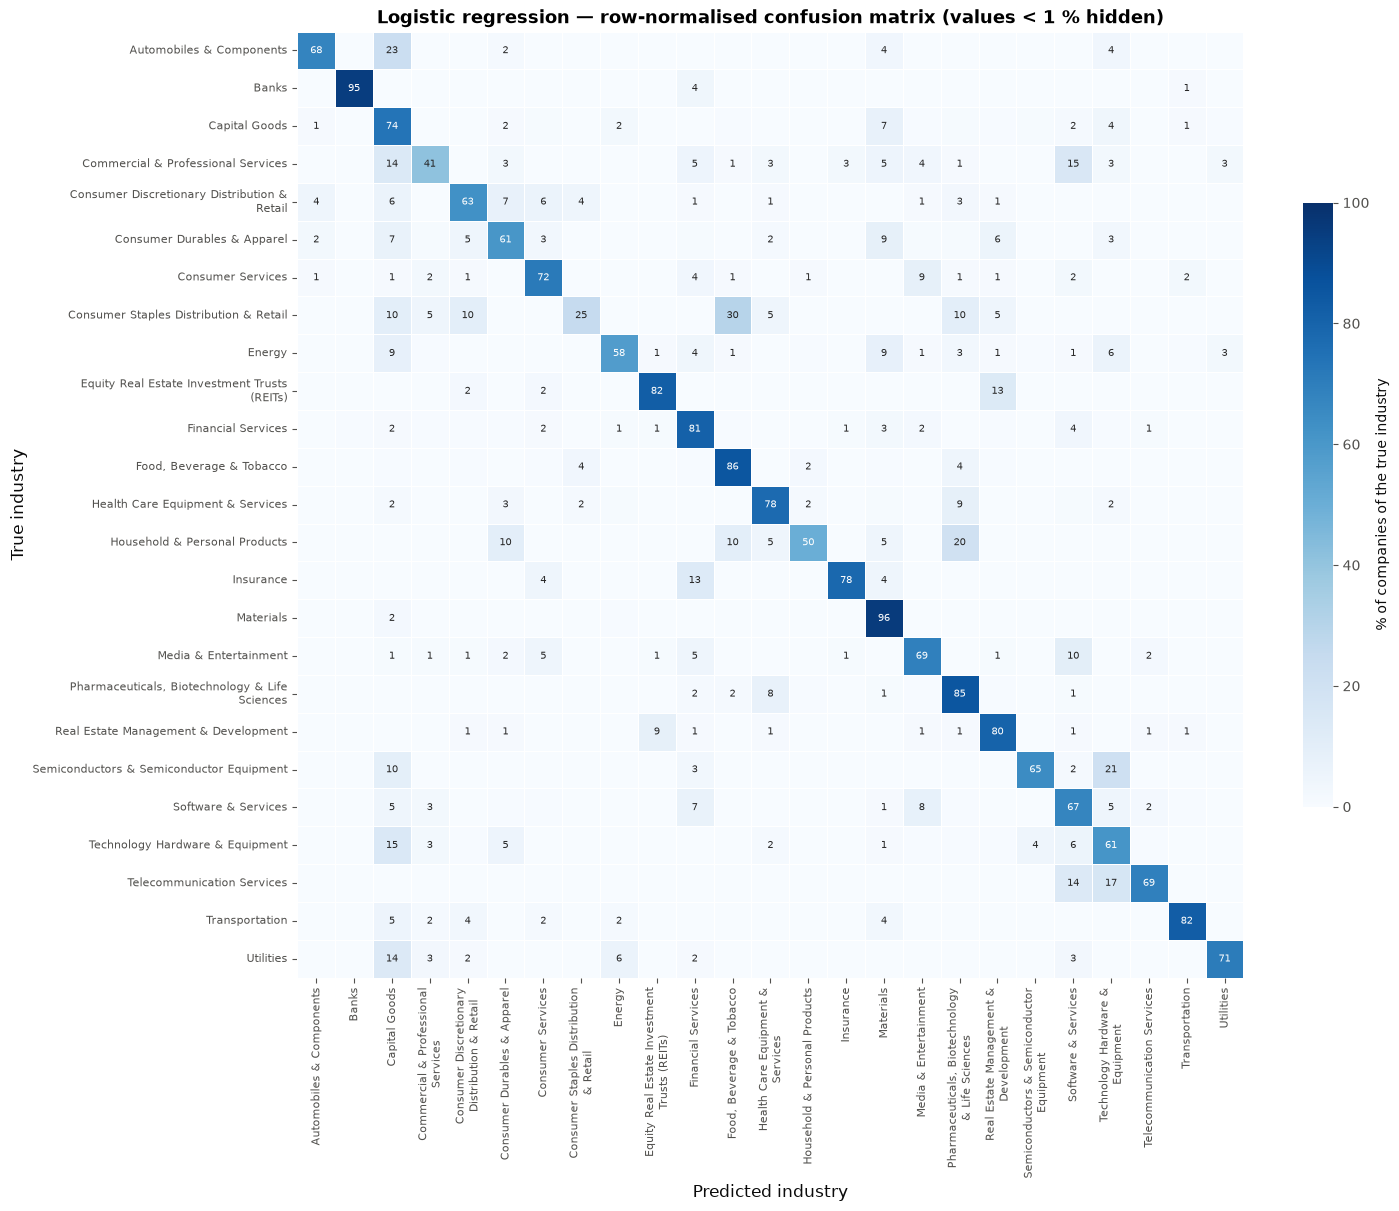

In [ ]:
def plot_confusion(y_true, y_pred, title, cmap):
    cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)), normalize="true") * 100
    fig, ax = plt.subplots(figsize=(15, 12.5))
    annot = np.where(cm >= 1, np.round(cm).astype(int).astype(str), "")
    sns.heatmap(cm, annot=annot, fmt="", cmap=cmap, vmin=0, vmax=100, square=True,
                linewidths=0.5, linecolor="white", annot_kws={"fontsize": 7.5},
                xticklabels=[short(c, 30) for c in CLASSES], yticklabels=[short(c, 40) for c in CLASSES],
                cbar_kws={"label": "% of companies of the true industry", "shrink": 0.6}, ax=ax)
    ax.set_xlabel("Predicted industry", fontsize=12)
    ax.set_ylabel("True industry", fontsize=12)
    ax.set_title(title, fontsize=13)
    plt.setp(ax.get_xticklabels(), rotation=90, fontsize=8)
    plt.setp(ax.get_yticklabels(), rotation=0, fontsize=8)
    ax.grid(False)
    plt.tight_layout()

plot_confusion(y_val, pred_lr, f"Logistic regression — row-normalised confusion matrix (values < 1 % hidden)", "Blues")

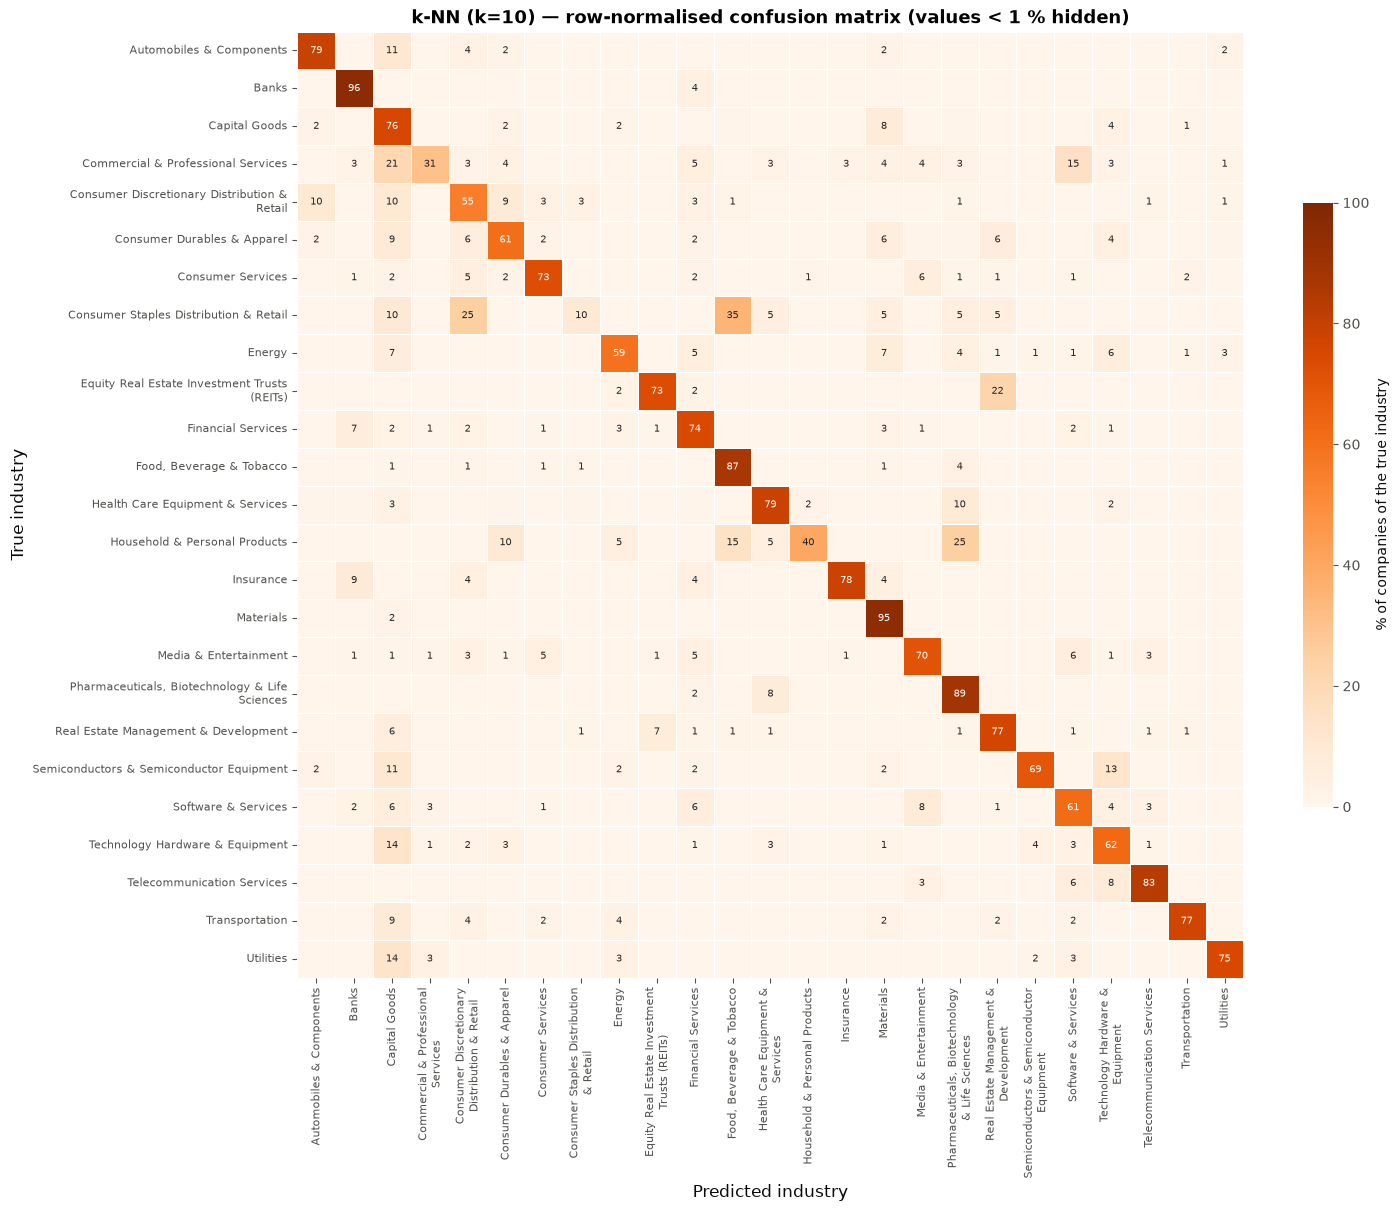

In [ ]:
plot_confusion(y_val, pred_knn, f"k-NN (k={best_k}) — row-normalised confusion matrix (values < 1 % hidden)", "Oranges")

In [ ]:
def top_confusions(y_true, y_pred, n=12):
    cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))
    rows = []
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            if i != j and cm[i, j] > 0:
                rows.append({"true industry": CLASSES[i], "predicted as": CLASSES[j],
                             "count": cm[i, j], "% of true class": 100 * cm[i, j] / cm[i].sum()})
    return pd.DataFrame(rows).sort_values("count", ascending=False).head(n).reset_index(drop=True)

print("Most frequent mistakes — logistic regression")
display(top_confusions(y_val, pred_lr).round(1))
print("Most frequent mistakes — k-NN")
display(top_confusions(y_val, pred_knn).round(1))

Most frequent mistakes — logistic regression


,true industry,predicted as,count,% of true class
0,Capital Goods,Materials,24,7.5
1,Technology Hardware & Equipment,Capital Goods,23,14.6
2,Materials,Capital Goods,17,2.2
3,"Pharmaceuticals, Biotechnology & Life Sciences",Health Care Equipment & Services,14,7.7
4,Semiconductors & Semiconductor Equipment,Technology Hardware & Equipment,13,21.0
5,Energy,Capital Goods,13,8.6
6,Capital Goods,Technology Hardware & Equipment,13,4.0
7,Energy,Materials,13,8.6
8,Commercial & Professional Services,Software & Services,12,15.4
9,Automobiles & Components,Capital Goods,12,22.6


Most frequent mistakes — k-NN


,true industry,predicted as,count,% of true class
0,Capital Goods,Materials,26,8.1
1,Technology Hardware & Equipment,Capital Goods,22,14.0
2,Commercial & Professional Services,Capital Goods,16,20.5
3,"Pharmaceuticals, Biotechnology & Life Sciences",Health Care Equipment & Services,14,7.7
4,Software & Services,Media & Entertainment,13,8.5
5,Materials,Capital Goods,13,1.6
6,Financial Services,Banks,13,6.6
7,Consumer Durables & Apparel,Capital Goods,12,9.4
8,Capital Goods,Technology Hardware & Equipment,12,3.7
9,Commercial & Professional Services,Software & Services,12,15.4


### Interpretation (confusion matrices): which industries are identified well, and which look similar?
* **Identified well** (diagonal ≥ 85 %): Materials (96 %), Banks (95 %), Food, Beverage & Tobacco (86 %), Pharma/Biotech (85 %); Financial Services, REITs, Transportation and Real Estate Management are around 80 %.
* **Capital Goods is a "sink" column.** Many industries leak into it: Automobiles & Components (23 % of them predicted as Capital Goods), Technology Hardware (15 %), Commercial & Professional Services (14 %), Utilities (14 %), Semiconductors (10 %), Energy (9 %). Capital Goods is the big, generic "makes industrial things" class, and many descriptions contain machinery/equipment/manufacturing words.
* **The confusions are economically sensible pairs** — most fall in the same broader sector:
  * Semiconductors → Technology Hardware (21 %); Telecom → Software & Services / Tech Hardware (14 % / 17 %)
  * Pharma/Biotech ↔ Health Care Equipment & Services (8 % / 9 %)
  * REITs ↔ Real Estate Management & Development (13 % / 9 %)
  * Insurance → Financial Services (13 %); Financial Services → Banks (k-NN)
  * Consumer Staples Distribution & Retail → Food, Beverage & Tobacco (30 %): a supermarket's description is full of food words
  * Capital Goods ↔ Materials: the single most frequent mistake in absolute numbers (24–26 companies), because both are large and both talk about industrial production
* **Both models show the same pattern**; k-NN is somewhat worse on the smallest consumer classes and on Commercial & Professional Services.
* Take-away: many errors are not "stupid" but sit on genuinely blurry industry borders, where even a human analyst might hesitate. These are exactly the cases a confidence score should flag for review.

## 8. Do both models misclassify the same companies?

### Questions to ask ourselves
* If both models fail on exactly the same companies, combining them cannot help. If their errors differ, an **ensemble** can fix some of them.
* Is the difference in accuracy between the two models **statistically significant**, or could it be luck of this particular validation set?
* When the two models **agree**, are they more often right? (That would be a natural confidence signal.)

### McNemar's test (paired comparison of two classifiers)
Both models are evaluated on the *same* companies, so we compare them pairwise with a 2×2 table:

| | kNN correct | kNN wrong |
|---|---|---|
| **LR correct** | $a$ | $b$ |
| **LR wrong** | $c$ | $d$ |

Only the **discordant** cases $b$ and $c$ carry information about which model is better. Under $H_0$ "both models have the same error rate", each discordant case is equally likely to fall into $b$ or $c$, so $b \sim \text{Binomial}(b+c,\ 0.5)$. The exact p-value is the probability of a split at least as lopsided as the one observed. A small p-value (< 0.05) means the accuracy difference is unlikely to be chance.

In [ ]:
lr_ok, knn_ok = pred_lr == y_val, pred_knn == y_val
table = pd.crosstab(pd.Series(np.where(lr_ok, "LR correct", "LR wrong"), name=""),
                    pd.Series(np.where(knn_ok, "kNN correct", "kNN wrong"), name=""))
display(table)

b, c = int((lr_ok & ~knn_ok).sum()), int((~lr_ok & knn_ok).sum())
p_mcnemar = stats.binomtest(b, b + c, 0.5).pvalue
print(f"discordant pairs: LR right & kNN wrong = {b},  LR wrong & kNN right = {c}")
print(f"McNemar exact test p-value = {p_mcnemar:.4f}")

err_lr, err_kn = set(np.where(~lr_ok)[0]), set(np.where(~knn_ok)[0])
both_wrong = ~lr_ok & ~knn_ok
print(f"\nerrors: LR {len(err_lr)}, kNN {len(err_kn)}, shared {len(err_lr & err_kn)}"
      f"  -> overlap (Jaccard) = {len(err_lr & err_kn) / len(err_lr | err_kn):.2f}")
print(f"when both are wrong, they predict the SAME wrong industry {np.mean(pred_lr[both_wrong] == pred_knn[both_wrong])*100:.0f} % of the time")
print(f"'oracle' accuracy (at least one model right) = {(lr_ok | knn_ok).mean():.3f}  <- upper bound for picking the right model per company")

,kNN correct,kNN wrong
,,
LR correct,2251,210
LR wrong,196,514


discordant pairs: LR right & kNN wrong = 210,  LR wrong & kNN right = 196
McNemar exact test p-value = 0.5189

errors: LR 710, kNN 724, shared 514  -> overlap (Jaccard) = 0.56
when both are wrong, they predict the SAME wrong industry 81 % of the time
'oracle' accuracy (at least one model right) = 0.838  <- upper bound for picking the right model per company


,share of companies,LR accuracy,kNN accuracy
models agree,0.841,0.844,0.844
models disagree,0.159,0.417,0.390


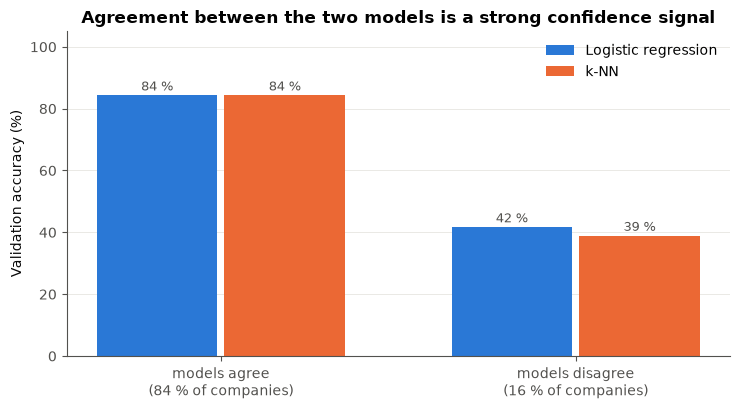

In [ ]:
agree = pred_lr == pred_knn
groups = pd.DataFrame({
    "share of companies": [agree.mean(), (~agree).mean()],
    "LR accuracy": [lr_ok[agree].mean(), lr_ok[~agree].mean()],
    "kNN accuracy": [knn_ok[agree].mean(), knn_ok[~agree].mean()],
}, index=["models agree", "models disagree"])
display(groups.round(3))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = np.arange(2)
ax.bar(x - 0.18, groups["LR accuracy"] * 100, width=0.34, color=C_LR, label="Logistic regression")
ax.bar(x + 0.18, groups["kNN accuracy"] * 100, width=0.34, color=C_KNN, label="k-NN")
for xi, (a_, k_) in enumerate(zip(groups["LR accuracy"], groups["kNN accuracy"])):
    ax.text(xi - 0.18, a_ * 100 + 1.5, f"{a_*100:.0f} %", ha="center", fontsize=9, color=INK2)
    ax.text(xi + 0.18, k_ * 100 + 1.5, f"{k_*100:.0f} %", ha="center", fontsize=9, color=INK2)
ax.set_xticks(x)
ax.set_xticklabels([f"models agree\n({groups.iloc[0,0]*100:.0f} % of companies)",
                    f"models disagree\n({groups.iloc[1,0]*100:.0f} % of companies)"])
ax.set_ylabel("Validation accuracy (%)")
ax.set_title("Agreement between the two models is a strong confidence signal")
ax.set_ylim(0, 105)
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="x", visible=False)
plt.tight_layout()

### Interpretation: do both models misclassify the same examples?
* **Largely yes.** 512 companies are wrong for both models: 72 % of logistic regression's errors and 71 % of k-NN's. The error sets overlap with a Jaccard index of 0.56. When both are wrong, they pick **the same wrong industry 81 % of the time** — these companies really do look like another industry in embedding space (ambiguous descriptions, border cases from Section 7, possibly a few label errors). No model built on the same embeddings will fix all of them.
* **But not entirely.** In 407 cases exactly one model is right (212 LR only, 195 k-NN only). If we could always pick the right model we would reach **83.9 % accuracy** — an upper bound that shows an ensemble has room to help.
* **McNemar's test: p = 0.43.** The split 212 vs 195 is very close to 50/50, so the small accuracy advantage of logistic regression is **not statistically significant** on this validation set. Both models perform equally well overall; logistic regression is preferable in practice (faster prediction, probabilities, better on tiny classes).
* **Agreement is a strong confidence signal:** the models agree on 84 % of companies, and there they are right 84.5 % of the time. When they disagree (16 %), each is right only about 40 % of the time. This is the natural starting point for the optional confidence task.

## 9. Preview of the bonus metric

The optional part scores $F_1^{\text{weighted}} \cdot (1-\text{Brier})$, where the Brier score $\frac1n\sum_i(\text{conf}_i - \mathbb 1[\text{correct}_i])^2$ punishes confidences that do not match the actual probability of being right. As a first look, we use each model's own predicted probability of its chosen class as the confidence.

In [ ]:
def confidence_score(y_true, y_pred, confidence):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    confidence = np.asarray(confidence, dtype=float)
    assert len(y_true) == len(y_pred) == len(confidence)
    assert np.all((confidence >= 0) & (confidence <= 1))
    f1 = f1_score(y_true, y_pred, average="weighted")
    brier = np.mean((confidence - (y_true == y_pred).astype(float)) ** 2)
    return f1 * (1 - brier)

conf_lr = lr.predict_proba(X_val).max(axis=1)
conf_knn = knn.predict_proba(X_val).max(axis=1)
print(f"logistic regression: score with its probability = {confidence_score(y_val, pred_lr, conf_lr):.4f}"
      f"   (with confidence 1.0: {confidence_score(y_val, pred_lr, np.ones(len(y_val))):.4f})")
print(f"k-NN:                score with its probability = {confidence_score(y_val, pred_knn, conf_knn):.4f}"
      f"   (with confidence 1.0: {confidence_score(y_val, pred_knn, np.ones(len(y_val))):.4f})")

logistic regression: score with its probability = 0.6673   (with confidence 1.0: 0.6000)
k-NN:                score with its probability = 0.6611   (with confidence 1.0: 0.5916)


* Using the model's own probability as confidence beats "always 1.0" for both models: an overconfident wrong prediction costs the full penalty $(1-0)^2 = 1$.
* Logistic regression already scores **≈ 0.67**, right at the "above 66 %" bar; k-NN is a bit lower. Its probabilities are reasonably calibrated because it is trained by minimising cross-entropy (a proper scoring rule, like Brier).
* Ideas for the optional part, motivated by what we found: (1) combine LR and k-NN probabilities; (2) use model agreement as a confidence feature (Section 8); (3) calibrate the confidence on held-out data; (4) give the template rows confidence ≈ 1; (5) add the financial ratios — after handling missing values, infinities and outliers — via per-industry distributions and p-values.

## 10. Summary — answers to the skeleton's questions

**Data.** 31,706 companies, 25 industries, one 768-dimensional unit-length embedding each; no missing values. 14 % of companies have a "template" embedding (one identical vector, almost always Materials), which inflates scores and distorts PCA. We kept these rows but report on real descriptions separately.

**Label encoding.** `LabelEncoder` maps the 25 names to 0–24; all validation industries occur in the training set.

**Over- or under-represented classes?** Yes, strongly: Materials is 26.6 %, the smallest class 0.6 % (48× imbalance). The majority baseline already reaches 24.9 % accuracy, so we report weighted and macro F1 too.

**Is there signal in the embeddings?** Yes. Even in a 2-D PCA projection (only ~25 % of the variance) several industries occupy clearly distinct regions, and a classifier on just 20 principal components already reaches 72 % accuracy (all 768 dimensions: 77 %).

**Model comparison.**

| | accuracy | weighted F1 | macro F1 |
|---|---|---|---|
| majority baseline | 0.249 | 0.099 | 0.016 |
| logistic regression (C=10) | 0.777 | 0.774 | 0.714 |
| k-NN (k=10) | 0.772 | 0.767 | 0.695 |

On real descriptions only, accuracy is ≈ 74 %. Logistic regression is marginally better, but McNemar's test (p = 0.43) says the difference is not significant.

**Do errors correlate with class representation?** Not significantly (Spearman ρ ≈ 0.17, p ≈ 0.4). Distinctive vocabulary matters more than size; only the very smallest class (Consumer Staples Distribution & Retail) clearly suffers, especially with k-NN.

**Which industries are identified well / which are similar?** Best: Materials, Banks, Food & Beverage, Pharma. Confused: neighbouring industries in the same sector — Semiconductors ↔ Tech Hardware, Pharma ↔ Health Care Equipment, REITs ↔ Real Estate Management, Insurance → Financial Services, grocery retail → Food producers — with Capital Goods acting as a sink for many industrial-sounding descriptions.

**Do both models misclassify the same examples?** Mostly: 72 % of errors are shared, usually with the same wrong label. But 407 companies are fixed by one of the two models (oracle 83.9 %), and when the models agree they are right 84.5 % of the time vs ~40 % when they disagree — a strong basis for an ensemble and a confidence score.

**Runtime.** Parsing ~5 s, logistic regression fit ~40 s, k-NN fit + predict ~2 s — far inside the 45-minute limit.